# Lead Scoring Analysis — X Education
**Student:** Gunda Uday kiran

## Objective
Build an interpretable logistic-regression model that assigns each lead a score from 0–100, evaluates model quality, and translates the results into business actions.

**Input:** `Leads.csv` (keep it in the same folder as this notebook when running the notebook).

In [1]:
# Core libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 100)


In [2]:
# Load the dataset.
# The notebook assumes Leads.csv is in the same folder.
df_raw = pd.read_csv("Leads.csv")

print("Shape:", df_raw.shape)
display(df_raw.head())
print("\nTarget distribution:")
display(df_raw["Converted"].value_counts().rename_axis("Converted").to_frame("Count"))


Shape: (9240, 37)


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,What matters most to you in choosing a course,Search,Magazine,Newspaper Article,X Education Forums,Newspaper,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Tags,Lead Quality,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,Page Visited on Website,NaN,Select,Select,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Interested in other courses,Low in Relevance,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,Email Opened,India,Select,Select,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Ringing,NaN,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,Email Opened,India,Business Administration,Select,Student,Better Career Prospects,No,No,No,No,No,No,No,No,Will revert after reading the email,Might be,No,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Ringing,Not Sure,No,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,Converted to Lead,India,Select,Other,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Will revert after reading the email,Might be,No,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified



Target distribution:


,Count
Converted,
0,5679
1,3561


## 1. Data quality and preparation

The dataset contains:
- 9,240 leads and 37 original columns.
- `Converted` is the binary target.
- `Select` is treated as missing because it means the respondent did not choose an option.
- Identifier columns are removed because they should not drive predictions.
- Constant columns are removed because they contain no predictive variation.
- Variables with more than 70% missing values are removed.
- Numeric missing values are median-imputed.
- Categorical missing values are mode-imputed inside the modelling pipeline.
- One-hot encoding is used for categorical variables and numeric variables are standardized.

In [3]:
# Treat 'Select' as a missing response.
df = df_raw.replace("Select", np.nan).copy()

# Quality checks.
print("Duplicate rows:", df.duplicated().sum())
print("Total missing cells:", int(df.isna().sum().sum()))

constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
high_missing_cols = df.isna().mean()[lambda s: s > 0.70].index.tolist()

print("\nConstant columns:")
print(constant_cols)

print("\nColumns with >70% missing values:")
print(high_missing_cols)

missing_summary = (
    df.isna().mean()
      .mul(100)
      .sort_values(ascending=False)
      .head(15)
      .rename("Missing %")
)
display(missing_summary.to_frame())


Duplicate rows: 0
Total missing cells: 54419

Constant columns:
['Magazine', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque']

Columns with >70% missing values:
['How did you hear about X Education', 'Lead Profile']


,Missing %
How did you hear about X Education,78.463203
Lead Profile,74.188312
Lead Quality,51.590909
Asymmetrique Profile Index,45.649351
Asymmetrique Activity Index,45.649351
Asymmetrique Activity Score,45.649351
Asymmetrique Profile Score,45.649351
City,39.707792
Specialization,36.580087
Tags,36.287879


In [4]:
# Remove identifiers, constant fields and very-high-missingness fields.
drop_cols = ["Prospect ID", "Lead Number"] + constant_cols + high_missing_cols

X = df.drop(columns=["Converted"] + drop_cols)
y = df["Converted"].astype(int)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Dropped columns:", drop_cols)
print("Final predictor columns:", X.shape[1])
print("Numeric predictors:", len(numeric_cols))
print("Categorical predictors:", len(categorical_cols))


Dropped columns: ['Prospect ID', 'Lead Number', 'Magazine', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque', 'How did you hear about X Education', 'Lead Profile']
Final predictor columns: 27
Numeric predictors: 5
Categorical predictors: 22


## 2. Exploratory analysis

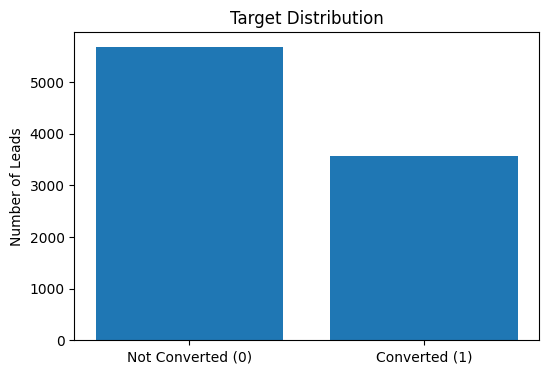

,count,median,mean
Converted,,,
0,5679,179.0,330.40
1,3561,832.0,738.55


In [5]:
# Target distribution
target_counts = df_raw["Converted"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Not Converted (0)", "Converted (1)"], target_counts.values)
plt.title("Target Distribution")
plt.ylabel("Number of Leads")
plt.show()

# Conversion rate by a key engagement variable.
display(
    df.groupby("Converted")["Total Time Spent on Website"]
      .agg(["count", "median", "mean"])
      .round(2)
)


## 3. Train/test split and preprocessing

A stratified 70:30 split is used so that the converted/non-converted mix remains comparable between train and test data. Preprocessing is fitted only on the training data through a `Pipeline`, preventing information from the test set from influencing imputation, scaling, or dummy creation.

In [6]:
train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.30,
    stratify=y,
    random_state=42
)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
    ]), categorical_cols)
])

print("Training observations:", len(train_idx))
print("Testing observations:", len(test_idx))


Training observations: 6468
Testing observations: 2772


## 4. Model selection

Logistic regression is appropriate because the business needs a probability that can be converted into a 0–100 lead score.

Two regularisation approaches are compared:
- **L1**: performs automatic variable selection by shrinking some coefficients to zero.
- **L2**: stabilises coefficients while retaining more variables.

The regularisation parameter `C` is tuned using five-fold stratified cross-validation and ROC-AUC. The holdout test set is kept separate for final evaluation.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_grid = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]

def tune_logistic(penalty):
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            penalty=penalty,
            solver="liblinear",
            max_iter=5000
        ))
    ])
    grid = GridSearchCV(
        pipe,
        {"model__C": C_grid},
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1
    )
    grid.fit(X.iloc[train_idx], y.iloc[train_idx])
    return grid

l1_grid = tune_logistic("l1")
l2_grid = tune_logistic("l2")

comparison = pd.DataFrame({
    "Model": ["L1 logistic regression", "L2 logistic regression"],
    "Best C": [l1_grid.best_params_["model__C"], l2_grid.best_params_["model__C"]],
    "Mean CV ROC-AUC": [l1_grid.best_score_, l2_grid.best_score_]
})
display(comparison.round(4))


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/daemon.py", line 112, in start_daemon
RuntimeError: Failed to start artifact tool daemon (exited early)


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/daemon.py", line 112, in start_daemon
RuntimeError: Failed to start artifact tool daemon (exited early)
Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/client.py", line 134, in call
BrokenPipeError: [Errno 32] Broken pipe

The above exception was the direct cause of the following exception:

Traceback (most recent 

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.L2TH2Y5coc/artifact_tool_v2-2.8.22/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


,Model,Best C,Mean CV ROC-AUC
0,L1 logistic regression,1,0.9677
1,L2 logistic regression,3,0.9676


### Final model choice

L1 regularisation is selected because it has the strongest cross-validated ROC-AUC and automatically reduces the feature set. This improves interpretability while retaining strong predictive performance.

In [8]:
model = l1_grid.best_estimator_
model.fit(X.iloc[train_idx], y.iloc[train_idx])

test_prob = model.predict_proba(X.iloc[test_idx])[:, 1]
test_pred = (test_prob >= 0.50).astype(int)

tn, fp, fn, tp = confusion_matrix(y.iloc[test_idx], test_pred).ravel()

metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y.iloc[test_idx], test_prob),
    "Accuracy": accuracy_score(y.iloc[test_idx], test_pred),
    "Precision": precision_score(y.iloc[test_idx], test_pred),
    "Recall": recall_score(y.iloc[test_idx], test_pred),
    "F1-score": f1_score(y.iloc[test_idx], test_pred)
})

display(metrics.round(4).to_frame("Holdout result"))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(np.array([[tn, fp], [fn, tp]]))
print("\nClassification report:")
print(classification_report(y.iloc[test_idx], test_pred, digits=3))


,Holdout result
ROC-AUC,0.9659
Accuracy,0.9123
Precision,0.8947
Recall,0.8755
F1-score,0.8850


Confusion matrix [[TN, FP], [FN, TP]]:
[[1594  110]
 [ 133  935]]

Classification report:
              precision    recall  f1-score   support

           0      0.923     0.935     0.929      1704
           1      0.895     0.875     0.885      1068

    accuracy                          0.912      2772
   macro avg      0.909     0.905     0.907      2772
weighted avg      0.912     0.912     0.912      2772



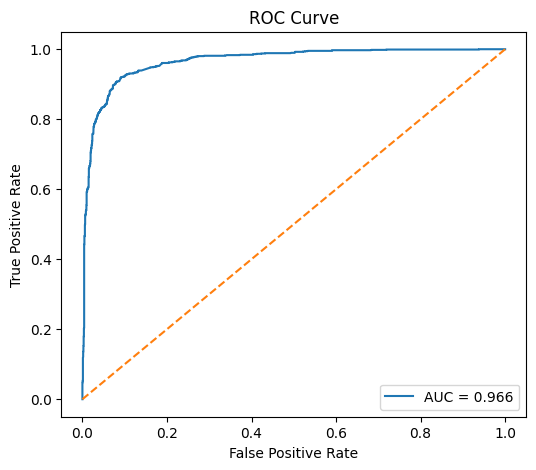

In [9]:
# ROC curve on the untouched holdout set.
fpr, tpr, _ = roc_curve(y.iloc[test_idx], test_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y.iloc[test_idx], test_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


## 5. Lead-score threshold strategy

The model outputs a probability. The default classification threshold is 0.50, but the business can change it depending on sales capacity:

- **Aggressive phase:** use a lower threshold to capture more potential converters.
- **Capacity-constrained phase:** use a higher threshold to reduce unnecessary calls.

Thresholds are evaluated on the same holdout set for transparent comparison.

In [10]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.80, 0.85]:
    pred = (test_prob >= threshold).astype(int)
    cm = confusion_matrix(y.iloc[test_idx], pred).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Predicted 1": int(pred.sum()),
        "Precision": precision_score(y.iloc[test_idx], pred, zero_division=0),
        "Recall": recall_score(y.iloc[test_idx], pred, zero_division=0),
        "F1": f1_score(y.iloc[test_idx], pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))


,Threshold,Predicted 1,Precision,Recall,F1
0,0.30,1172,0.8464,0.9288,0.8857
1,0.50,1045,0.8947,0.8755,0.8850
2,0.80,815,0.9534,0.7275,0.8253
3,0.85,767,0.9570,0.6873,0.8000


## 6. Variable importance and model interpretation

Permutation importance is used at the original-variable level because it is easier for business users to interpret than a long list of one-hot dummy coefficients. Coefficients are also inspected to identify the strongest positive categorical signals.

**Important caution:** variables such as `Tags` and `Lead Quality` describe lead status/quality and may be assigned after sales-team interaction. If those fields are not available at the exact moment a new lead is scored, they should be excluded from a production version to avoid information leakage.

In [11]:
perm = permutation_importance(
    model,
    X.iloc[test_idx],
    y.iloc[test_idx],
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = (
    pd.DataFrame({
        "Variable": X.columns,
        "Permutation Importance": perm.importances_mean
    })
    .sort_values("Permutation Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df.head(10).round(5))


,Variable,Permutation Importance
0,Tags,0.16696
1,Total Time Spent on Website,0.03112
2,Lead Quality,0.02521
3,Asymmetrique Activity Score,0.02443
4,Last Notable Activity,0.02270
5,Lead Origin,0.01043
6,Asymmetrique Activity Index,0.00783
7,Last Activity,0.00707
8,What is your current occupation,0.00652
9,Lead Source,0.00211


In [12]:
# Inspect the strongest positive categorical/dummy coefficients.
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["model"].coef_[0]

dummy_coefficients = pd.DataFrame({
    "Dummy": feature_names,
    "Coefficient": coefficients
})

top_positive_dummies = (
    dummy_coefficients[
        (dummy_coefficients["Dummy"].str.startswith("cat__")) &
        (dummy_coefficients["Coefficient"] > 0)
    ]
    .sort_values("Coefficient", ascending=False)
    .head(10)
)

display(top_positive_dummies)
print("Non-zero model coefficients:", int(np.count_nonzero(coefficients)))


,Dummy,Coefficient
109,cat__Tags_Lost to EINS,9.241135
101,cat__Tags_Closed by Horizzon,7.958442
118,cat__Tags_Will revert after reading the email,3.663542
135,cat__Asymmetrique Activity Index_03.Low,3.199541
108,cat__Tags_Lateral student,2.517417
134,cat__Asymmetrique Activity Index_02.Medium,2.131808
100,cat__Tags_Busy,2.081385
19,cat__Lead Source_Welingak Website,2.040651
6,cat__Lead Origin_Lead Add Form,1.954410
103,cat__Tags_Graduation in progress,1.477710


Non-zero model coefficients: 69


## 7. Generate 0–100 lead scores

The probability of conversion is multiplied by 100. The resulting score is continuous and can be sorted from highest to lowest for sales prioritisation.

In [13]:
# Refit the selected model on all historical observations before scoring all leads.
final_model = l1_grid.best_estimator_
final_model.fit(X, y)

all_prob = final_model.predict_proba(X)[:, 1]

lead_scores = df_raw[["Prospect ID", "Lead Number"]].copy()
lead_scores["Lead Score"] = np.round(all_prob * 100, 1)
lead_scores["Conversion Probability"] = np.round(all_prob, 4)
lead_scores["Predicted Conversion"] = (all_prob >= 0.50).astype(int)

lead_scores = lead_scores.sort_values("Lead Score", ascending=False)
display(lead_scores.head(20))

# Optional output for downstream use:
lead_scores.to_csv("lead_scores_output.csv", index=False)


,Prospect ID,Lead Number,Lead Score,Conversion Probability,Predicted Conversion
6005,b8390e1a-6a8b-4b59-92a3-d3df435ae4fb,603713,100.0,0.9996,1
693,e68e2ea2-3cad-4678-88bf-22979eebcd9e,653415,100.0,0.9999,1
2533,6836d63b-3b70-4960-9ee6-825eaaec46f5,635362,100.0,0.9999,1
6017,5e8b601c-8118-4d05-9c97-09c026e946e9,603637,100.0,0.9998,1
2936,2f32df46-504d-4249-8052-5b322b5aabcc,631563,100.0,0.9997,1
3078,2e1ff385-d334-420f-a530-8074e95032b2,630427,100.0,0.9997,1
737,4e85a82c-fff0-4de6-9c37-8b0609888736,652801,100.0,0.9995,1
7490,50f485d9-fe6b-463b-a933-3b46629609f2,592198,100.0,0.9996,1
7482,55e4867b-7f32-4944-b7ef-4727e167b066,592240,100.0,0.9998,1
6125,de393f4f-c7bf-4a9c-8ede-719862556b7e,602757,100.0,0.9999,1


## 8. Business recommendations

1. Use the lead score to rank leads instead of calling the entire pool equally.
2. During the intern-heavy aggressive period, lower the threshold toward 0.30 and prioritise the highest scores first; this increases recall.
3. When the quarterly target is already achieved, raise the threshold toward 0.80–0.85 to improve precision and reduce unnecessary calls.
4. Review score-band conversion rates every month and recalibrate thresholds when conversion behaviour or lead mix changes.
5. Before production deployment, verify that every predictor used by the model is available **before** the sales action being optimised. Remove any post-contact status fields that are not available at scoring time.
